In [24]:
%load_ext autoreload
%autoreload 2
from notebook_cache import NotebookCache

cache = NotebookCache('../cache/dreamzero')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# DreamZero, small, built from scratch on T1

DreamZero = a pretrained **video** model (Wan, 14B) taught to also output **actions**: one transformer denoises the next frames and the next actions together. Here everything is ours and tiny, and the video model learns only T1.

The bet: video is cheap, labels are not. Does a video model pretrained on lots of T1 video make actions learnable from few labelled demos?

```-
stage               trains on                               learns
1  video model      80 demos, frames only                   what happens next in T1   (our "Wan")
2  world-action     10 labelled demos, frames + actions     actions, on top of stage 1
baseline            stage 2 alone, from random weights      (uwm2: 10 labelled -> 30/40)
```

DreamZero's recipe (paper sec. 3.1, app. C): a demo is cut into **chunks** (K frames + the H actions that span them). Chunk k is noised to one level τ_k shared by its frames and actions, and denoised while seeing the **clean** chunks before it (teacher forcing). In the sim, the real frames replace the dreamed ones after each chunk is played.

### step 0 — the data: 100 demos, uwm2's split


In [25]:
import numpy as np
from frozendict import frozendict
from uwm_parts import load_table, load_top

NAME = 'pick_place_cube_n100'

In [26]:
@cache
def table():
    return load_table(NAME)  # state [N, 8], action [N, 8], episode [N]

table: cached, 1 call(s) stored


In [27]:
@cache
def images():
    return load_top(NAME)  # [N, 3, 128, 128] uint8, top camera, a few minutes the first time

images: cached, 1 call(s) stored


In [28]:
def split():
    # episode ids, as uwm2: 10 held out, 10 labelled, the other 80 frames only
    val = np.random.default_rng(0).permutation(100)[:10]
    train = np.setdiff1d(np.arange(100), val)
    labelled = np.random.default_rng(1).choice(train, 10, replace=False)
    return frozendict(val=val, labelled=labelled, video=np.setdiff1d(train, labelled))


state, action, episode = table()
top = images()
eps = split()
print(f'{top.shape=}  demo length {np.bincount(episode).min()}..{np.bincount(episode).max()} steps')
print({k: len(v) for k, v in eps.items()})

top.shape=(21295, 3, 128, 128)  demo length 197..237 steps
{'val': 10, 'labelled': 10, 'video': 80}


### step 1 — a demo cut into chunks

A sample = the frame now, then M = 4 chunks. Chunk k = the H = 16 actions it plays and the K = 2 frames they lead through (one every 8 steps). Training will denoise chunk k while it sees the clean chunks before it.


In [29]:
K, H, M = 2, 16, 4  # frames per chunk, actions per chunk, chunks per sample


def chunks_of(e: int, start: int):
    # rows of demo e from step `start`: the frame now, then M chunks of K frames + H actions
    now = np.flatnonzero(episode == e)[0] + start
    return frozendict(
        now=now,
        frames=now + H // K * np.arange(1, M * K + 1).reshape(M, K),  # [M, K], every 8 steps
        acts=now + np.arange(M * H).reshape(M, H),  # [M, H]
    )


ex = chunks_of(int(eps['labelled'][0]), start=40)
print(f'now {ex["now"]}\nframes\n{ex["frames"]}\nactions first/last\n{ex["acts"][:, [0, -1]]}')

now 6631
frames
[[6639 6647]
 [6655 6663]
 [6671 6679]
 [6687 6695]]
actions first/last
[[6631 6646]
 [6647 6662]
 [6663 6678]
 [6679 6694]]


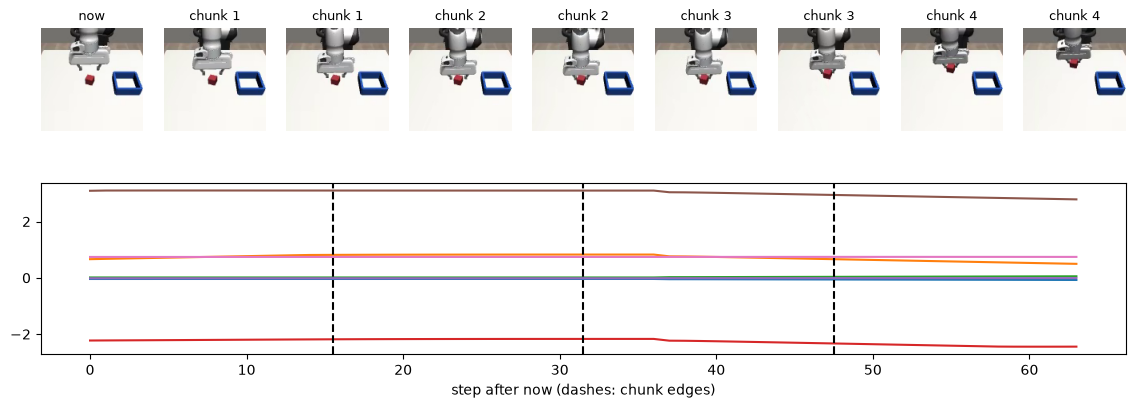

In [30]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(14, 4.5))
grid = fig.add_gridspec(2, 1 + M * K, height_ratios=[1, 1.2])
rows = [ex['now']] + list(ex['frames'].flatten())
for i, row in enumerate(rows):
    ax = fig.add_subplot(grid[0, i])
    ax.imshow(np.transpose(top[row], (1, 2, 0)))
    ax.set_title('now' if i == 0 else f'chunk {(i - 1) // K + 1}', fontsize=9)
    ax.axis('off')
ax = fig.add_subplot(grid[1, :])
ax.plot(action[ex['acts'].flatten(), :7])  # the 7 arm joints, 64 steps
for k in range(1, M):
    ax.axvline(k * H - 0.5, color='k', ls='--')
ax.set_xlabel('step after now (dashes: chunk edges)')
plt.show()

### step 2 — a batch: many samples at random demos and moments

Everything on the GPU once (~1 GB of frames). Each sample: the 9 frames (now + 4 chunks × 2), the 4 × 16 actions, and the joints at the start of each chunk (DreamZero's state input, q_k).


In [95]:
from dataclasses import dataclass

import torch
from torch import Tensor

dev = 'cuda'
gpu = frozendict(
    top=torch.tensor(top, device=dev),  # [N, 3, 128, 128] uint8
    state=torch.tensor(state, device=dev),  # [N, 8]
    action=torch.tensor(action, device=dev),  # [N, 8]
)


@dataclass(frozen=True, kw_only=True)
class Batch:
    frames: Tensor  # [B, 9, 3, 128, 128] uint8: now, then every 8 steps
    acts: Tensor  # [B, M, H, 8]
    state: Tensor  # [B, M, 8], at each chunk's first step


def get_batch(ids: np.ndarray, B: int, rng: np.random.Generator):
    # B samples from demos `ids`, each at a random moment with room for M chunks after it
    first, lens = np.searchsorted(episode, np.arange(100)), np.bincount(episode)
    e = rng.choice(ids, B)
    now = first[e] + rng.integers(0, lens[e] - M * H)  # [B]
    frames = now[:, None] + H // K * np.arange(M * K + 1)  # [B, 9]: now, then every 8 steps
    acts = now[:, None] + np.arange(M * H)  # [B, 64]
    return Batch(
        frames=gpu['top'][frames],
        acts=gpu['action'][acts].view(B, M, H, 8),
        state=gpu['state'][acts[:, ::H]],
    )

In [96]:
b = get_batch(eps['labelled'], 32, np.random.default_rng(0))
print({k: tuple(v.shape) for k, v in vars(b).items()})
print(f'frames per batch {b.frames.numel() / 2**20:.0f} MB (uint8)')

{'frames': (32, 9, 3, 128, 128), 'acts': (32, 4, 16, 8), 'state': (32, 4, 8)}
frames per batch 14 MB (uint8)


### step 3 — a batch as tokens

The transformer reads a list of D-dim vectors. Dumb version, no compressor yet: each frame is cut into 8 × 8 squares of 16 px, each square flattened (3·16·16 = 768 numbers) and mapped to D by one linear layer. Each action and each chunk's joints get their own linear layer. Pixels go to [−1, 1], actions and joints to std units (stats from the labelled demos only).


In [44]:
from einops import rearrange

P = 16  # patch side: 128 px -> 8 x 8 patches per frame
lab = torch.tensor(np.isin(episode, eps['labelled']), device=dev)  # [N]
stats = frozendict(
    a_mean=gpu['action'][lab].mean(0), a_std=gpu['action'][lab].std(0),
    s_mean=gpu['state'][lab].mean(0), s_std=gpu['state'][lab].std(0),
)


def patches(x: torch.Tensor) -> torch.Tensor:
    # [..., 3, 128, 128] uint8 -> [..., 64, 768] in [-1, 1], one row per 16 x 16 square
    x = x.float() / 255 * 2 - 1
    return rearrange(x, '... c (h p) (w q) -> ... (h w) (p q c)', p=P, q=P)

In [97]:
from torch import nn

D = 128  # token width
torch.set_grad_enabled(False)  # steps 3-8 only look; training turns it back on
torch.manual_seed(0)
embed = nn.ModuleDict(
    dict(frame=nn.Linear(3 * P * P, D), action=nn.Linear(8, D), state=nn.Linear(8, D))
).to(dev)
tok = frozendict(
    frame=embed['frame'](patches(b.frames)),  # [B, 9, 64, D]
    action=embed['action']((b.acts - stats['a_mean']) / stats['a_std']),  # [B, 4, 16, D]
    state=embed['state']((b.state - stats['s_mean']) / stats['s_std']),  # [B, 4, D]
)
print({k: tuple(v.shape) for k, v in tok.items()})

{'frame': (32, 9, 64, 128), 'action': (32, 4, 16, 128), 'state': (32, 4, 128)}


In [58]:
# one sample's order: now, then per chunk [joints, 2 frames, 16 actions]
parts = [('now', tok['frame'][:, 0])]
for k in range(M):
    parts += [
        (f'state {k + 1}', tok['state'][:, k, None]),
        (f'frames {k + 1}', tok['frame'][:, 1 + K * k : 1 + K * (k + 1)].flatten(1, 2)),
        (f'acts {k + 1}', tok['action'][:, k]),
    ]
print('  '.join(f'{name}:{x.shape[1]}' for name, x in parts))
print(f'total {sum(x.shape[1] for _, x in parts)} tokens per sample')

now:64  state 1:1  frames 1:128  acts 1:16  state 2:1  frames 2:128  acts 2:16  state 3:1  frames 3:128  acts 3:16  state 4:1  frames 4:128  acts 4:16
total 644 tokens per sample


### step 4 — who may look at whom (paper fig. 14a)

In training the sequence holds each chunk twice. **Clean** C_k: chunk k's 2 real frames, the history later chunks see (C0 = now). **Noisy** chunk k: its joints, its 2 frames and 16 actions with noise added, to be denoised. Rules:

```-
clean C_j     sees clean C_0 .. C_j                          (causal, never the noisy ones)
noisy k       sees clean C_0 .. C_(k-1)  +  its own block    (the past as it really was)
```


In [59]:
# the training sequence: (name, tokens, time, noisy)
layout = [('C0', 64, 0, False)]
for k in range(1, M + 1):
    layout += [(f'chunk {k}', 1 + K * 64 + H, k, True)]  # joints, frames, actions
    if k < M:
        layout += [(f'C{k}', K * 64, k, False)]
t = torch.tensor([time for _, n, time, _ in layout for _ in range(n)])  # [T]
noisy = torch.tensor([nz for _, n, _, nz in layout for _ in range(n)])  # [T]
# mask[q, k]: may query q look at key k
key_noisy, q_noisy = noisy[None, :], noisy[:, None]
same_chunk = t[None, :] == t[:, None]
clean_before = t[None, :] <= t[:, None] - q_noisy.long()  # noisy k: clean C_0..C_(k-1)
mask = torch.where(key_noisy, q_noisy & same_chunk, clean_before)
print(f'{len(t)} tokens   {[(name, n) for name, n, _, _ in layout]}')

1028 tokens   [('C0', 64), ('chunk 1', 145), ('C1', 128), ('chunk 2', 145), ('C2', 128), ('chunk 3', 145), ('C3', 128), ('chunk 4', 145)]


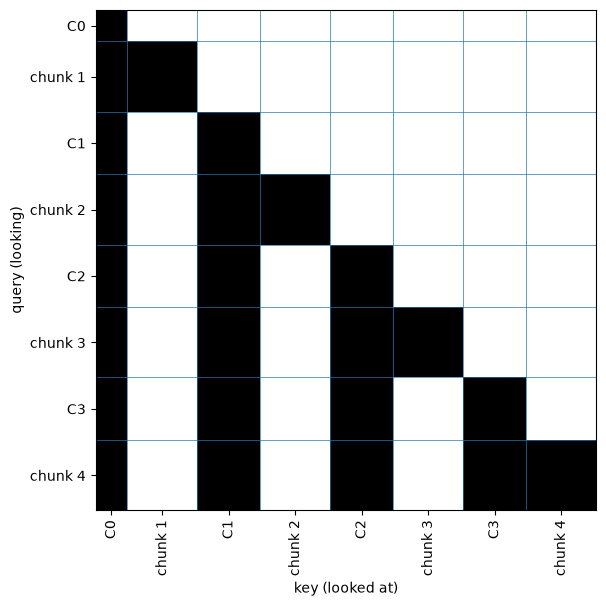

In [60]:
edges = np.cumsum([0] + [n for _, n, _, _ in layout])
mids = (edges[:-1] + edges[1:]) / 2
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(mask, cmap='Greys', interpolation='nearest')
names = [name for name, *_ in layout]
ax.set_xticks(mids, names, rotation=90)
ax.set_yticks(mids, names)
ax.set_xlabel('key (looked at)')
ax.set_ylabel('query (looking)')
for e in edges[1:-1]:
    ax.axhline(e - 0.5, color='tab:blue', lw=0.5)
    ax.axvline(e - 0.5, color='tab:blue', lw=0.5)
plt.show()

### step 5 — one noise level per chunk, shared by its frames and actions

Flow matching's line, as in uwm: `x_τ = (1 − τ)·noise + τ·clean` (τ = 0 pure noise, 1 clean). Each chunk draws its own τ_k; its 2 frames and 16 actions share it (paper eq. 2).


In [98]:
torch.manual_seed(0)
frames = b.frames[:, 1:].float().view(32, M, K, 3, 128, 128)  # now dropped: chunk frames only
clean = frozendict(
    frames=frames / 255 * 2 - 1,  # [B, 4, 2, 3, 128, 128]
    acts=(b.acts - stats['a_mean']) / stats['a_std'],  # [B, 4, 16, 8]
)
tau = torch.rand(32, M, device=dev)  # [B, 4], one per chunk
tf, ta = tau.view(32, M, 1, 1, 1, 1), tau.view(32, M, 1, 1)  # broadcast to frames, actions
noise = frozendict(frames=torch.randn_like(clean['frames']), acts=torch.randn_like(clean['acts']))
noisy = frozendict(
    frames=(1 - tf) * noise['frames'] + tf * clean['frames'],
    acts=(1 - ta) * noise['acts'] + ta * clean['acts'],
)
print(f'sample 0, tau per chunk: {tau[0].cpu().numpy().round(2)}')

sample 0, tau per chunk: [0.4  0.52 0.02 0.94]


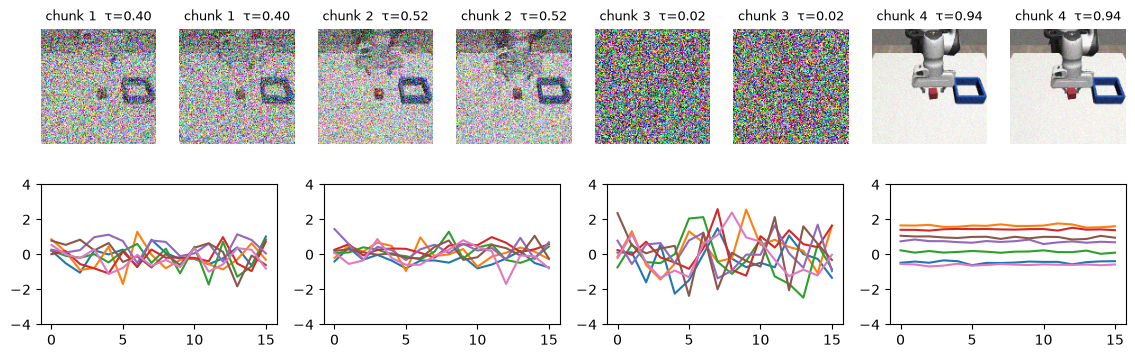

In [62]:
fig, axs = plt.subplots(2, M * K, figsize=(14, 4))
for k in range(M):
    for j in range(K):
        ax = axs[0, K * k + j]
        ax.imshow(((noisy['frames'][0, k, j].permute(1, 2, 0) + 1) / 2).clamp(0, 1).cpu())
        ax.set_title(f'chunk {k + 1}  τ={tau[0, k]:.2f}', fontsize=9)
        ax.axis('off')
    ax = fig.add_subplot(2, M, M + k + 1)
    ax.plot(noisy['acts'][0, k, :, :7].cpu())  # 7 arm joints, std units
    ax.set_ylim(-4, 4)
for ax in axs[1]:
    ax.remove()
plt.show()

### step 6 — one forward pass, loose pieces

New pieces: τ → a D-vector added to every token of its chunk (so the net knows how noisy that chunk is), a learned position per token, a small transformer run with the step-4 mask, and two output layers that read the noisy chunks back: patch velocity (768) and action velocity (8).


In [63]:
torch.manual_seed(0)
layer = nn.TransformerEncoderLayer(
    D, nhead=4, dim_feedforward=4 * D, dropout=0.0, activation='gelu', batch_first=True,
    norm_first=True,
)
core = nn.ModuleDict(
    dict(
        tau=nn.Linear(1, D),  # noise level -> added to its chunk's tokens
        pos=nn.Embedding(len(t), D),  # one learned position per token
        body=nn.TransformerEncoder(layer, num_layers=4, enable_nested_tensor=False),
        frame_out=nn.Linear(D, 3 * P * P),  # velocity of each patch
        action_out=nn.Linear(D, 8),  # velocity of each action
    )
).to(dev)
n_params = sum(p.numel() for m in (embed, core) for p in m.parameters())
print(f'{n_params / 1e6:.2f}M params')

1.13M params


In [99]:
# the 1028-token training sequence for batch b: C0, chunk 1, C1, chunk 2, ..., chunk 4
noisy_patches = rearrange(
    noisy['frames'], 'b m k c (h p) (w q) -> b m (k h w) (p q c)', p=P, q=P
)  # [B, 4, 128, 768]
blocks = [tok['frame'][:, 0]]  # C0: now, clean
for k in range(M):
    chunk = [
        tok['state'][:, k, None],  # joints at the chunk's start
        embed['frame'](noisy_patches[:, k]),
        embed['action'](noisy['acts'][:, k]),
    ]
    blocks.append(torch.cat(chunk, 1) + core['tau'](tau[:, k, None])[:, None])
    if k < M - 1:
        blocks.append(tok['frame'][:, 1 + K * k : 1 + K * (k + 1)].flatten(1, 2))  # C_(k+1)
x = torch.cat(blocks, 1) + core['pos'].weight  # [B, 1028, D]
print(f'{x.shape=}')

x.shape=torch.Size([32, 1028, 128])


In [100]:
starts = edges[1::2]  # where each noisy chunk begins in the sequence
idx = frozendict(
    frame=torch.tensor(np.stack([s + 1 + np.arange(K * 64) for s in starts])),  # [4, 128]
    action=torch.tensor(np.stack([s + 1 + K * 64 + np.arange(H) for s in starts])),  # [4, 16]
)
h = core['body'](x, mask=~mask.to(dev))  # torch's mask: True = blocked
v = frozendict(
    frames=core['frame_out'](h[:, idx['frame']]),  # [B, 4, 128, 768]
    acts=core['action_out'](h[:, idx['action']]),  # [B, 4, 16, 8]
)
print({k: tuple(x.shape) for k, x in v.items()})

{'frames': (32, 4, 128, 768), 'acts': (32, 4, 16, 8)}


### step 7 — the loss, and a check that the future doesn't leak

Target velocity = clean − noise (the straight line's slope, paper eq. 3); loss = MSE on frames and on actions. Then: change chunk 4's input, and nothing outside chunk 4 may change.


In [69]:
import torch.nn.functional as F

to_patch = 'b m k c (h p) (w q) -> b m (k h w) (p q c)'
target = frozendict(
    frames=rearrange(clean['frames'] - noise['frames'], to_patch, p=P, q=P),  # [B, 4, 128, 768]
    acts=clean['acts'] - noise['acts'],  # [B, 4, 16, 8]
)
loss = {k: round(F.mse_loss(v[k], target[k]).item(), 3) for k in v}
size = {k: round(target[k].square().mean().item(), 3) for k in target}  # loss if v were 0
print(f'untrained loss {loss}\ntarget mean square {size}')

untrained loss {'frames': 2.606, 'acts': 3.055}
target mean square {'frames': 1.66, 'acts': 1.912}


In [70]:
x2 = x.clone()
x2[:, edges[7] :] += torch.randn_like(x2[:, edges[7] :])  # scramble chunk 4 (the last block)
h2 = core['body'](x2, mask=~mask.to(dev))
diff = (h2 - h).abs().amax(dim=(0, 2))  # [1028], biggest change per token
before, inside = diff[: edges[7]].max().item(), diff[edges[7] :].max().item()
print(f'max change before chunk 4: {before:.1e}   inside chunk 4: {inside:.2f}')

max change before chunk 4: 0.0e+00   inside chunk 4: 5.07


### step 8 — the pieces packed: `WAM` and `batch_loss`

Same layers as steps 3–6 in one module; `batch_loss` does step 5's noising, the pass, and step 7's loss. Noising in patch space = noising pixels, then cutting (it's elementwise). Check: given step 6's weights and inputs, `WAM` must give the same outputs.


In [71]:
class WAM(nn.Module):
    # steps 3-6 packed: tokens -> masked transformer -> velocities of the noisy chunks
    def __init__(self):
        super().__init__()
        self.frame_in, self.action_in = nn.Linear(3 * P * P, D), nn.Linear(8, D)
        self.state_in, self.tau_in = nn.Linear(8, D), nn.Linear(1, D)
        self.pos = nn.Embedding(len(t), D)
        layer = nn.TransformerEncoderLayer(
            D, nhead=4, dim_feedforward=4 * D, dropout=0.0, activation='gelu', batch_first=True,
            norm_first=True,
        )
        self.body = nn.TransformerEncoder(layer, num_layers=4, enable_nested_tensor=False)
        self.frame_out, self.action_out = nn.Linear(D, 3 * P * P), nn.Linear(D, 8)
        self.register_buffer('blocked', ~mask)  # step 4, torch's convention: True = blocked
        self.register_buffer('at_frames', idx['frame'])  # [4, 128] noisy frame tokens
        self.register_buffer('at_acts', idx['action'])  # [4, 16] noisy action tokens

    def forward(self, seen, state, noisy_f, noisy_a, tau):
        # seen [B, 9, 64, 768] clean patches (now, then the chunks' frames); state [B, M, 8]
        # noisy_f [B, M, 128, 768], noisy_a [B, M, H, 8], tau [B, M]
        f = self.frame_in(seen)
        blocks = [f[:, 0]]  # C0
        for k in range(M):
            chunk = [
                self.state_in(state[:, k, None]),
                self.frame_in(noisy_f[:, k]),
                self.action_in(noisy_a[:, k]),
            ]
            blocks.append(torch.cat(chunk, 1) + self.tau_in(tau[:, k, None])[:, None])
            if k < M - 1:
                blocks.append(f[:, 1 + K * k : 1 + K * (k + 1)].flatten(1, 2))  # C_(k+1)
        h = self.body(torch.cat(blocks, 1) + self.pos.weight, mask=self.blocked)
        return self.frame_out(h[:, self.at_frames]), self.action_out(h[:, self.at_acts])

In [101]:
def batch_loss(net: WAM, b: Batch) -> tuple[torch.Tensor, torch.Tensor]:
    # steps 5-7 for a batch from get_batch: (frame loss, action loss)
    B = len(b.frames)
    seen = patches(b.frames)  # [B, 9, 64, 768]
    clean_f = seen[:, 1:].reshape(B, M, K * 64, 3 * P * P)
    clean_a = (b.acts - stats['a_mean']) / stats['a_std']
    state = (b.state - stats['s_mean']) / stats['s_std']
    tau = torch.rand(B, M, device=dev)
    noise_f, noise_a = torch.randn_like(clean_f), torch.randn_like(clean_a)
    tf, ta = tau.view(B, M, 1, 1), tau.view(B, M, 1, 1)
    v_f, v_a = net(
        seen, state, (1 - tf) * noise_f + tf * clean_f, (1 - ta) * noise_a + ta * clean_a, tau
    )
    return F.mse_loss(v_f, clean_f - noise_f), F.mse_loss(v_a, clean_a - noise_a)

In [102]:
net = WAM().to(dev)
loose = dict(
    frame_in=embed['frame'], action_in=embed['action'], state_in=embed['state'], tau_in=core['tau'],
    pos=core['pos'], body=core['body'], frame_out=core['frame_out'], action_out=core['action_out'],
)
for name, m in loose.items():
    getattr(net, name).load_state_dict(m.state_dict())  # step 6's weights
state_n = (b.state - stats['s_mean']) / stats['s_std']
out = net(patches(b.frames), state_n, noisy_patches, noisy['acts'], tau)
diff = [(out[0] - v['frames']).abs().max().item(), (out[1] - v['acts']).abs().max().item()]
print(f'max diff vs step 6 (frames, acts): {diff}')
print(f'batch_loss (fresh noise): {[round(x.item(), 3) for x in batch_loss(net, b)]}')

max diff vs step 6 (frames, acts): [1.9073486328125e-06, 7.152557373046875e-07]
batch_loss (fresh noise): [2.602, 3.092]


### step 9 — first training run: joint, on the 10 labelled demos only

The dumb whole game, no video pretraining yet. Batch 16, bf16, AdamW lr 3e-4, grad clip 1, 5k steps. Val = 32 fixed samples from the 10 held-out demos, every 500 steps.


In [78]:
@cache
def train(steps: int = 5000, B: int = 16, lr: float = 3e-4, seed: int = 0):
    # prints (frame, action) losses; out: weights (CPU),
    # log rows [step, train frame, train act, val frame, val act]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = WAM().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                lf, la = batch_loss(net, get_batch(eps['labelled'], B, rng))
            opt.zero_grad()
            (lf + la).backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    val_b = get_batch(eps['val'], 32, np.random.default_rng(1))
                    vf, va = batch_loss(net, val_b)
                log.append([step, lf.item(), la.item(), vf.item(), va.item()])
                print(f'{step:5d}  train {lf:.3f} {la:.3f}   val {vf:.3f} {va:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train: not cached, will compute


In [79]:
run = train()

    0  train 2.558 2.470   val 2.461 2.673
  500  train 1.083 0.205   val 1.086 0.316
 1000  train 1.044 0.134   val 1.050 0.194
 1500  train 1.036 0.098   val 1.035 0.205
 2000  train 1.026 0.094   val 1.025 0.192
 2500  train 1.012 0.081   val 1.015 0.185
 3000  train 1.006 0.082   val 1.005 0.148
 3500  train 0.995 0.065   val 0.999 0.152
 4000  train 0.993 0.085   val 0.991 0.134
 4500  train 0.981 0.046   val 0.985 0.153
 5000  train 0.979 0.094   val 0.981 0.160


### step 10 — the dreams: chunk 1 denoised from pure noise

Given only the real now-frame and joints, start chunk 1 at τ = 0 and take 10 Euler steps to τ = 1 (flow_matching.ipynb). Chunks 2–4 can't reach chunk 1 (step 4's mask), so they stay noise; the clean future frames are zeroed to be sure.


In [103]:
@torch.no_grad()
def dream(net: WAM, frames: Tensor, state: Tensor, steps: int = 10):
    # chunk 1 from noise, given frames [B, 9, 3, 128, 128] uint8 (only [:, 0] read), raw joints
    # state [B, M, 8]; out: frame patches [B, 128, 768] in [-1, 1], actions [B, 16, 8] std units
    B = len(frames)
    seen = patches(frames)
    seen[:, 1:] = 0  # only now is known
    state = (state - stats['s_mean']) / stats['s_std']
    x_f = torch.randn(B, M, K * 64, 3 * P * P, device=dev)
    x_a = torch.randn(B, M, H, 8, device=dev)
    tau = torch.zeros(B, M, device=dev)
    for i in range(steps):
        tau[:, 0] = i / steps
        v_f, v_a = net(seen, state, x_f, x_a, tau)
        x_f[:, 0] += v_f[:, 0] / steps
        x_a[:, 0] += v_a[:, 0] / steps
    return x_f[:, 0], x_a[:, 0]

In [104]:
net = WAM().to(dev)
net.load_state_dict(run['weights'])
torch.manual_seed(0)
val_b = get_batch(eps['val'], 32, np.random.default_rng(2))
d_f, d_a = dream(net, val_b.frames, val_b.state)
real = patches(val_b.frames)
real_f = real[:, 1 : 1 + K].flatten(1, 2)  # [B, 128, 768] chunk 1's 2 frames
real_a = (val_b.acts[:, 0] - stats['a_mean']) / stats['a_std']
mse = lambda x, y: ((x - y) / 2).square().mean().item()  # pixels in [0, 1] units
copy_now = mse(real[:, 0].repeat(1, K, 1), real_f)
print(f'frames: dream {mse(d_f, real_f):.4f}   copy now {copy_now:.4f}')
print(f'actions (std units): dream {(d_a - real_a).square().mean():.3f}')

frames: dream 0.2462   copy now 0.0148
actions (std units): dream 0.045


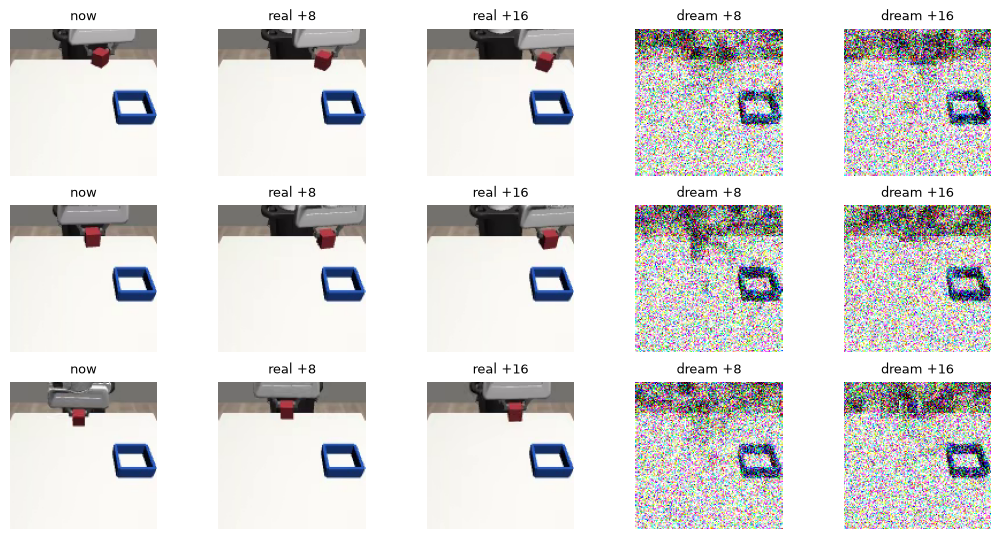

In [82]:
to_img = lambda x: (
    rearrange((x + 1) / 2, '(k h w) (p q c) -> k h p w q c', k=K, h=8, p=P, q=P)
    .flatten(1, 2)
    .flatten(2, 3)
    .clamp(0, 1)
    .cpu()
)  # [128, 768] -> [K, 128, 128, 3]
fig, axs = plt.subplots(3, 1 + 2 * K, figsize=(13, 6.5))
for r in range(3):
    ims = [to_img(real[r, 0].repeat(K, 1))[0], *to_img(real_f[r]), *to_img(d_f[r])]
    names = ['now', 'real +8', 'real +16', 'dream +8', 'dream +16']
    for ax, im, name in zip(axs[r], ims, names):
        ax.imshow(im)
        ax.set_title(name, fontsize=9)
        ax.axis('off')
plt.show()

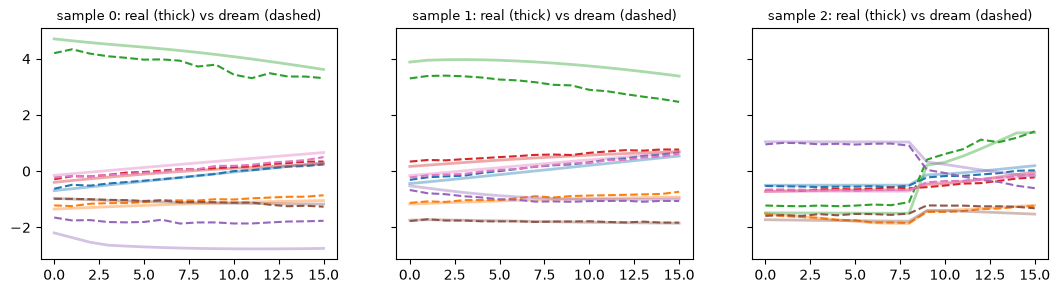

In [83]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for r, ax in enumerate(axs):
    for j in range(7):
        line = ax.plot(real_a[r, :, j].cpu(), lw=2, alpha=0.4)[0]
        ax.plot(d_a[r, :, j].cpu(), '--', color=line.get_color())
    ax.set_title(f'sample {r}: real (thick) vs dream (dashed)', fontsize=9)
plt.show()

### step 11 — rollout in T1: the dumb whole game's number

Policy: dream chunk 1 from the current frame and joints (step 10), play its first `n_exec` actions, dream again. Same 20 env seeds (1000–1019) and n_exec 8 / 16 as uwm2 (10 labelled: 16 + 14 = 30/40).


In [105]:
from collections import Counter

from uwm_parts import make_sim

env = make_sim()


def act(net: WAM, obs) -> np.ndarray:
    # current top frame + joints -> [16, 8] actions, chunk 1 dreamed
    frame = torch.from_numpy(obs.images['top']).permute(2, 0, 1).to(dev)  # [3, 128, 128] uint8
    frames = frame.expand(1, 1 + M * K, -1, -1, -1)  # only [:, 0] is read
    state = torch.from_numpy(obs.state).to(dev).expand(1, M, -1)
    _, d_a = dream(net, frames, state)
    chunk = (d_a * stats['a_std'] + stats['a_mean'])[0].cpu().numpy()
    chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)  # gripper commands stay in [0, 1]
    return chunk


def rollout(net: WAM, seed: int, n_exec: int, seen: list | None = None) -> tuple[bool, str, int]:
    # seen: if given, every top frame is appended to it
    obs, plan = env.reset(seed=seed), []
    for step in range(600):
        if seen is not None:
            seen.append(obs.images['top'])
        if not plan:
            plan = list(act(net, obs)[:n_exec])
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1

In [85]:
@cache
def sweep(n_exec: int) -> dict[int, tuple]:
    # step 9's weights over env seeds 1000-1019; out: {seed: (ok, mode, steps)}
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout(net, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}'
    )
    return res

sweep: not cached, will compute


In [86]:
sweeps = {n_exec: sweep(n_exec) for n_exec in [8, 16]}
print('uwm2, UWMxx on the same 10 labelled demos: 16, 14')

n_exec  8:  2/20   failures {'wrong_target': 6, 'dropped': 1, 'no_grasp': 11}
n_exec 16:  2/20   failures {'no_grasp': 11, 'wrong_target': 7}
uwm2, UWMxx on the same 10 labelled demos: 16, 14


### step 12 — control: the same run, actions only

`train` with the frame loss switched off (still printed). If the sim score jumps toward uwm2's 30/40, the broken frame half was dragging the actions down.


In [87]:
@cache
def train_acts(steps: int = 5000, B: int = 16, lr: float = 3e-4, seed: int = 0):
    # train with the frame loss switched off; prints (frame, action) losses; out: weights (CPU),
    # log rows [step, train frame, train act, val frame, val act]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = WAM().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                lf, la = batch_loss(net, get_batch(eps['labelled'], B, rng))
            opt.zero_grad()
            la.backward()  # frame loss logged, not trained
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    val_b = get_batch(eps['val'], 32, np.random.default_rng(1))
                    vf, va = batch_loss(net, val_b)
                log.append([step, lf.item(), la.item(), vf.item(), va.item()])
                print(f'{step:5d}  train {lf:.3f} {la:.3f}   val {vf:.3f} {va:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_acts: not cached, will compute


In [88]:
run_acts = train_acts()

    0  train 2.558 2.470   val 2.637 2.736
  500  train 3.338 0.226   val 3.366 0.352
 1000  train 3.460 0.143   val 3.468 0.209
 1500  train 3.538 0.107   val 3.647 0.230
 2000  train 3.732 0.097   val 3.766 0.226
 2500  train 3.808 0.081   val 3.776 0.200
 3000  train 3.872 0.079   val 3.808 0.172
 3500  train 3.883 0.066   val 3.925 0.166
 4000  train 3.983 0.085   val 3.969 0.145
 4500  train 3.931 0.037   val 4.042 0.179
 5000  train 4.123 0.092   val 4.102 0.174


In [89]:
runs = {'joint': run, 'acts': run_acts}


@cache
def sweep_run(name: str, n_exec: int) -> dict[int, tuple]:
    # step 11's sweep with runs[name]'s weights; out: {seed: (ok, mode, steps)}
    net = WAM().to(dev)
    net.load_state_dict(runs[name]['weights'])
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout(net, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}'
    )
    return res

sweep_run: not cached, will compute


In [90]:
sweeps_acts = {n_exec: sweep_run('acts', n_exec) for n_exec in [8, 16]}
print('joint (step 11): 2, 2   uwm2 UWMxx: 16, 14')

n_exec  8:  0/20   failures {'no_grasp': 20}
n_exec 16:  0/20   failures {'no_grasp': 20}
joint (step 11): 2, 2   uwm2 UWMxx: 16, 14


### step 13 — watch one rollout: where does it go wrong?

Joint model (step 9), env seed 1000, n_exec 8. A frame every 25 steps, and the video.


(False, 'wrong_target', 600)


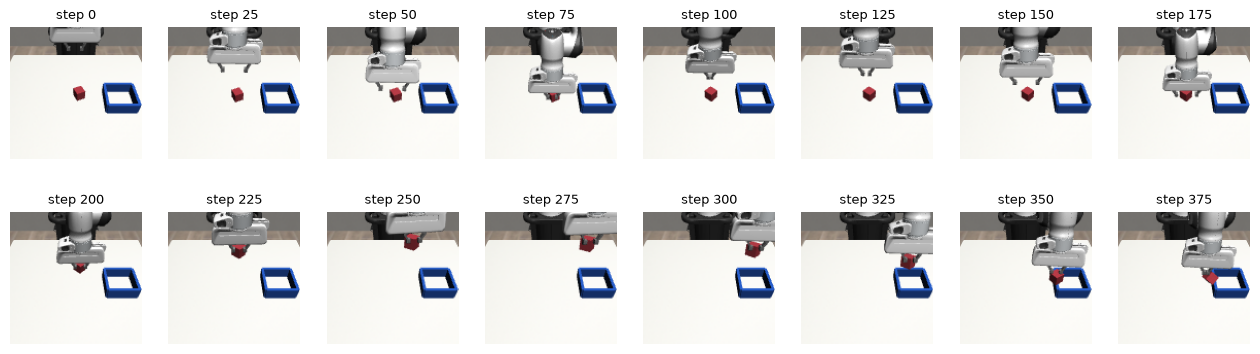

In [92]:
torch.manual_seed(8)
seen = []
print(rollout(net, 1000, 8, seen))  # net = step 9's weights (loaded in step 10)
fig, axs = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, i in zip(axs.flat, range(0, len(seen), 25)):
    ax.imshow(seen[i])
    ax.set_title(f'step {i}', fontsize=9)
    ax.axis('off')
plt.show()

In [93]:
import imageio
from IPython.display import Video

imageio.mimsave('../scratch/dreamzero_seed1000.mp4', seen, fps=20)
Video('../scratch/dreamzero_seed1000.mp4', embed=True, width=320)

### step 14 — the rollout knew the task, just imprecise: train as long as uwm2

Seed 1000 (step 13): reached, missed the first grasp, grasped on the second try, carried, set it on the bin's rim. uwm2 saw 10k × 64 = 640k samples; step 9 saw 80k. Same 640k here as 20k × 32 (64 may not fit in 8 GB).


In [94]:
run_long = train(steps=20000, B=32)
runs['long'] = run_long

    0  train 2.553 2.445   val 2.443 2.576
  500  train 1.085 0.213   val 1.086 0.317
 1000  train 1.047 0.123   val 1.045 0.191
 1500  train 1.035 0.099   val 1.033 0.183
 2000  train 1.022 0.095   val 1.024 0.162
 2500  train 1.014 0.061   val 1.015 0.182
 3000  train 1.008 0.103   val 1.006 0.174
 3500  train 0.995 0.041   val 0.998 0.170
 4000  train 0.988 0.070   val 0.991 0.131
 4500  train 0.982 0.040   val 0.983 0.120
 5000  train 0.975 0.047   val 0.975 0.157
 5500  train 0.969 0.038   val 0.968 0.155
 6000  train 0.963 0.050   val 0.967 0.163
 6500  train 0.961 0.049   val 0.959 0.147
 7000  train 0.957 0.085   val 0.956 0.166
 7500  train 0.948 0.033   val 0.957 0.206
 8000  train 0.945 0.035   val 0.946 0.175
 8500  train 0.944 0.055   val 0.943 0.143
 9000  train 0.942 0.039   val 0.941 0.161
 9500  train 0.939 0.046   val 0.940 0.182
10000  train 0.932 0.040   val 0.936 0.161
10500  train 0.926 0.038   val 0.937 0.205
11000  train 0.928 0.035   val 0.927 0.171
11500  trai

In [106]:
sweeps_long = {n_exec: sweep_run('long', n_exec) for n_exec in [8, 16]}
print('joint 5k (step 11): 2, 2   uwm2 UWMxx: 16, 14')

n_exec  8:  1/20   failures {'wrong_target': 14, 'dropped': 5}
n_exec 16:  9/20   failures {'wrong_target': 7, 'no_grasp': 3, 'dropped': 1}
joint 5k (step 11): 2, 2   uwm2 UWMxx: 16, 14
